# Simulate variable-density and tilted anisotropic acoustic waves

Two second-order equations that need first derivatives. Variable density, `p_tt = vp^2 rho div(grad(p) / rho)` written out as `vp^2 (laplace(p) - grad(rho) . grad(p) / rho)`, takes first derivatives of the field (`p.dx`) and of the model (`rho.dx`); elliptic TTI takes the mixed derivative `p.dz.dx`. In the first, a density step alone reflects; in the second, tilting the symmetry axis tilts the wavefront.

In [1]:
import base64

import numpy as np
import sympy
import torch
from IPython.display import HTML

from sweep.propagator.options import EagerOptions, Full
from sweep.propagator.torch import PropTorch
from sweep.symbolic import PDE, Coefficient, Eq, Field, Model, laplace

dev = "cuda" if torch.cuda.is_available() else "cpu"
torch.backends.cudnn.allow_tf32 = False                 # full fp32 stencils
opts = EagerOptions(use_compile=False)

Helpers: a Ricker wavelet, a run that keeps snapshots, and a GIF writer.

In [2]:
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter


def ricker(nt, dt, f0):
    a = (np.pi * f0 * (np.arange(nt) * dt - 1.5 / f0)) ** 2
    return torch.tensor((1 - 2 * a) * np.exp(-a), dtype=torch.float32)


def snapshots(solver, wavelet, sources, receivers, models, every=10, **kwargs):
    """Run one batch; return the record, every field every `every` steps (cropped to the model) and the times."""
    steps = list(range(every - 1, solver.nt, every))
    with torch.no_grad():
        record, snap = solver(wavelet, sources, receivers, models=models, return_wavefield=True,
                              snapshot_times=steps, **kwargs)
    nz, nx = models[0].shape[-2:]
    x0, _, z0, _ = solver._runtime_padding()
    if snap.shape[-2] - nz < z0 or snap.shape[-1] - nx < x0:   # padding not as reported: centre the crop
        z0, x0 = (snap.shape[-2] - nz) // 2, (snap.shape[-1] - nx) // 2
    snap = snap[..., z0:z0 + nz, x0:x0 + nx]
    names = [f.name for f in solver.equation.field_specs]
    frames = {n: snap[:, i, :, 0].numpy() for i, n in enumerate(names) if not n.startswith("_")}
    return record.cpu(), frames, (np.array(steps) + 1) * float(solver.dt)


def save_gif(path, panels, times, extent, xlabel="x (km)", ylabel="z (km)", unit="s", cmap="seismic",
             clip=99.8, outline=None, normalize=False, share=False):
    """Animate panels [(title, frames (nframe, nz, nx))] with fixed colour limits; outline: a model drawn as contours;
    share: one colour scale for every panel."""
    aspect = abs(extent[1] - extent[0]) / abs(extent[2] - extent[3])
    fig, axes = plt.subplots(1, len(panels), figsize=((3.2 * aspect + 0.45) * len(panels), 3.6),
                             squeeze=False, constrained_layout=True)
    outlines = outline if isinstance(outline, list) else [outline] * len(panels)
    images = []
    for k, (ax, (title, data), line) in enumerate(zip(axes[0], panels, outlines)):
        if normalize:
            data = data / np.abs(data).max(axis=(1, 2), keepdims=True).clip(min=1e-30)
        if cmap == "seismic":
            a = np.percentile(np.abs(np.stack([d for _, d in panels]) if share else data), clip) or 1.0
            lo, hi = -a, a
        else:
            lo, hi = np.percentile(data, [100 - clip, clip])
        im = ax.imshow(data[0], cmap=cmap, vmin=lo, vmax=hi, extent=extent, interpolation="bilinear")
        if line is not None:
            ax.contour(line, levels=6, colors="k", linewidths=0.5, alpha=0.35, extent=extent, origin="upper")
        ax.set(title=title, xlabel=xlabel)
        if k == 0:
            ax.set_ylabel(ylabel)
        else:
            ax.tick_params(labelleft=False)
        images.append((im, data))
    clock = fig.suptitle("")

    def draw(i):
        for im, data in images:
            im.set_data(data[i])
        clock.set_text(f"t = {times[i]:.3g} {unit}")

    FuncAnimation(fig, draw, frames=len(times)).save(path, writer=PillowWriter(fps=10), dpi=70)
    plt.close(fig)
    return path


def show_gif(path):
    """Show a GIF inline; as HTML, so the docs site renders it too."""
    data = base64.b64encode(open(path, "rb").read()).decode()
    return HTML(f'<img src="data:image/gif;base64,{data}">')

## The PDE

Declare the models and fields, write one equation per field, and build the equation class.

In [3]:
vp, rho = Model("vp"), Model("rho")
p = Field("p", source=True, receiver=True)

pde = PDE([Eq(p.dt2, vp**2 * (laplace(p) - (rho.dx * p.dx + rho.dz * p.dz) / rho))], name="VarDensity")
VarDensity = pde.build(ndim=2)
pde

PDE([Eq(p.dt2, vp**2*(laplace(p) - (rho.dx*p.dx + rho.dz*p.dz)/rho))], name='VarDensity')

## Run it

A velocity of 2000 m/s everywhere and two densities in one batch: constant on the left, a smooth step from 1000 to 2500 kg/m³ at 1 km depth on the right (the expanded form wants a density smooth on the scale of the stencil).

In [4]:
n, h, dt, nt, f0 = 201, 10.0, 1e-3, 700, 15.0
z = np.arange(n)[:, None] * np.ones((1, n))
step = 1000 + 1500 / (1 + np.exp(-(z - 100) / 1.5))
vp_b = torch.full((2, n, n), 2000.0, device=dev)
rho_b = torch.tensor(np.stack([np.full((n, n), 1000.0), step]), dtype=torch.float32, device=dev)

solver = PropTorch(VarDensity(8, device=dev), shape=(n, n), dh=h, dt=dt, nt=nt, dev=dev,
                   impl="eager", memory=Full(), eager_options=opts)
src = np.array([[n // 2, 50]] * 2)
rec = np.array([[[ix, 50] for ix in range(n)]] * 2)
record, frames, t = snapshots(solver, ricker(nt, dt, f0), src, rec, [vp_b, rho_b], every=14,
                              max_vel=2000.0, pml_freq=f0)

## The wavefield

The right shot reflects at the density step; the left one passes on.


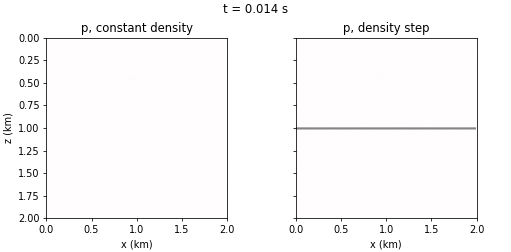

In [5]:
ext = [0, (n - 1) * h / 1e3, (n - 1) * h / 1e3, 0]
gif = save_gif("84_symbolic_variable_density.gif", [("p, constant density", frames["p"][:, 0]),
                                                    ("p, density step", frames["p"][:, 1])],
               t, ext, outline=[None, (z > 100).astype(float)], share=True)
show_gif(gif)

## Elliptic TTI: a mixed derivative

The elliptic anisotropic equation with its symmetry axis tilted by `theta` from the vertical; `epsilon` stretches the wavefront along the symmetry plane. The tilt brings in the mixed derivative `p.dz.dx`.

In [6]:
eps, theta = Model("epsilon"), Model("theta")
cs, sn = sympy.cos(theta), sympy.sin(theta)

tti = PDE([Eq(p.dt2, vp**2 * (((1 + 2 * eps) * cs**2 + sn**2) * p.dx2
                               + ((1 + 2 * eps) * sn**2 + cs**2) * p.dz2
                               - 2 * eps * sympy.sin(2 * theta) * p.dz.dx))], name="EllipticTTI")
EllipticTTI = tti.build(ndim=2)
tti

PDE([Eq(p.dt2, vp**2*(-2*epsilon*sin(2*theta)*p.dz.dx + ((2*epsilon + 1)*sin(theta)**2 + cos(theta)**2)*p.dz2 + ((2*epsilon + 1)*cos(theta)**2 + sin(theta)**2)*p.dx2))], name='EllipticTTI')

Two shots in one batch with epsilon = 0.25: an untilted axis on the left, a tilt of 30° on the right.


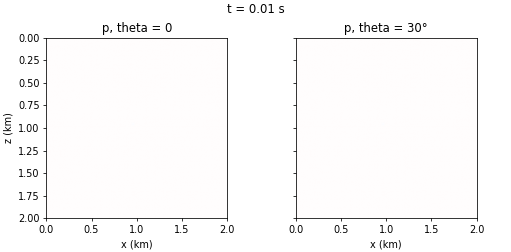

In [7]:
eps_b = torch.full((2, n, n), 0.25, device=dev)
theta_b = torch.stack([torch.zeros(n, n), torch.full((n, n), np.pi / 6)]).to(dev)
solver = PropTorch(EllipticTTI(8, device=dev), shape=(n, n), dh=h, dt=dt, nt=500, dev=dev,
                   impl="eager", memory=Full(), eager_options=opts)
src = np.array([[n // 2, n // 2]] * 2)
rec = np.array([[[n // 2, n // 2]]] * 2)
_, frames, t = snapshots(solver, ricker(500, dt, f0), src, rec, [vp_b, eps_b, theta_b], every=10,
                         max_vel=2000.0 * np.sqrt(1.5), pml_freq=f0)
gif = save_gif("84_symbolic_tti.gif", [("p, theta = 0", frames["p"][:, 0]), ("p, theta = 30°", frames["p"][:, 1])],
               t, ext)
show_gif(gif)